In [3]:
pip install pandas numpy matplotlib scikit-learn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 7.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 14.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


    Clients  Publicite  Reduction  Chiffre_Affaires
0        50         20          0               500
1        60         30          5               620
2        45         15          0               440
3        70         40         10               780
4        80         50          5               850
5        55         25          5               570
6        90         60         10               980
7        65         35          0               650
8        75         45          5               800
9        40         10          0               390
10       85         55         10               940
11      100         70         15              1150
12       58         28          0               580
13       95         65          5              1050
14       68         38         10               760
Dimensions : (15, 4)
Les cinq premières lignes du DataFrame :
   Clients  Publicite  Reduction  Chiffre_Affaires
0       50         20          0               500
1   

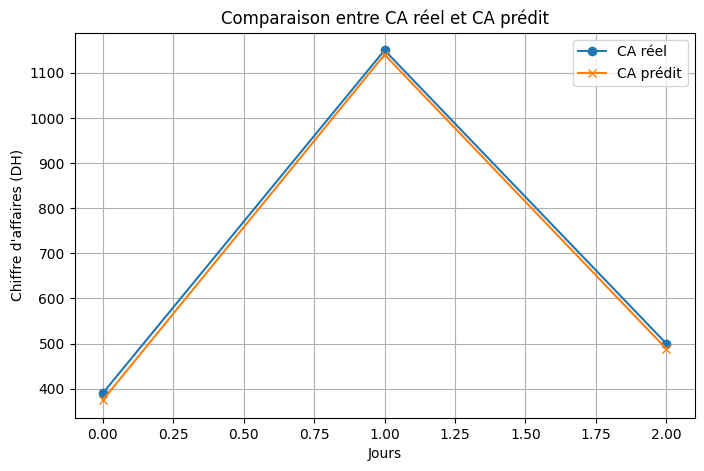

Chiffre d'affaires prévu : 857.5718597400377 DH
Chiffre d'affaires prévu : 914.515453937159 DH
    Clients  Publicite  Reduction  Commandes_Livrees  Chiffre_Affaires
0        50         20          0                 12               500
1        60         30          5                 15               620
2        45         15          0                 10               440
3        70         40         10                 20               780
4        80         50          5                 22               850
5        55         25          5                 14               570
6        90         60         10                 25               980
7        65         35          0                 17               650
8        75         45          5                 21               800
9        40         10          0                  9               390
10       85         55         10                 24               940
11      100         70         15                 30 

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
data = {
    'Clients': [50, 60, 45, 70, 80, 55, 90, 65, 75, 40, 85, 100, 58, 95, 68],
    'Publicite': [20, 30, 15, 40, 50, 25, 60, 35, 45, 10, 55, 70, 28, 65, 38],
    'Reduction': [0, 5, 0, 10, 5, 5, 10, 0, 5, 0, 10, 15, 0, 5, 10],
    'Chiffre_Affaires': [500, 620, 440, 780, 850, 570, 980, 650, 800, 390, 940, 1150, 580, 1050, 760]
}

df = pd.DataFrame(data)
print("Les cinq premières lignes du DataFrame :")
print(df.head())

print("\nLes dimensions du DataFrame :")
print(df.shape)

print("\nLes informations sur le DataFrame :")
print(df.info())

print("\nLes valeurs manquantes dans le DataFrame :")
print(df.isnull().sum())

X = df[['Clients', 'Publicite', 'Reduction']]
y = df['Chiffre_Affaires']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("\nCoefficients du modèle :")
print(model.coef_)
print("\nInterception du modèle :")
print(model.intercept_)
y_pred = model.predict(X_test)
resultats = pd.DataFrame({
 'CA Reel': y_test.values,
'CA Prevu': y_pred
})
print(resultats)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"\nMAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
plt.figure(figsize=(8, 5))
plt.plot(
 range(len(y_test)),
 y_test.values,
 marker='o',
 label='CA réel'
)
plt.plot(
 range(len(y_pred)),
 y_pred,
 marker='x',
 label='CA prédit'
)
plt.xlabel("Jours")
plt.ylabel("Chiffre d'affaires (DH)")
plt.title("Comparaison entre CA réel et CA prédit")
plt.legend()
plt.grid()
plt.show()

nouvelle_journee = pd.DataFrame({
 'Clients': [85],
 'Publicite': [45],
 'Reduction': [5]
})
prediction = model.predict(nouvelle_journee)
print("Chiffre d'affaires prévu :", prediction[0], "DH")

nouvelle_journee2 = pd.DataFrame({
 'Clients': [95],
 'Publicite': [45],
 'Reduction': [5]
})
prediction = model.predict(nouvelle_journee2)
print("Chiffre d'affaires prévu :", prediction[1], "DH")







In [13]:
# Amélioration du modèle

data2 = {
    'Clients': [
        50, 60, 45, 70, 80, 55, 90, 65, 75, 40,
        85, 100, 58, 95, 68, 72, 88, 60, 105, 78
    ],

    'Publicite': [
        20, 30, 15, 40, 50, 25, 60, 35, 45, 10,
        55, 70, 28, 65, 38, 42, 58, 30, 75, 48
    ],

    'Reduction': [
        0, 5, 0, 10, 5, 5, 10, 0, 5, 0,
        10, 15, 0, 5, 10, 5, 10, 0, 15, 5
    ],

    'Commandes_Livrees': [
        12, 15, 10, 20, 22, 14, 25, 17, 21, 9,
        24, 30, 14, 27, 19, 20, 24, 15, 32, 22
    ],

    'Chiffre_Affaires': [
        500, 620, 440, 780, 850, 570, 980, 650, 800, 390,
        940, 1150, 580, 1050, 760, 730, 920, 610, 1250, 820
    ]
}

# Création du DataFrame
df = pd.DataFrame(data2)

print(df)

# Définition de X et y
X = df[['Clients', 'Publicite', 'Reduction', 'Commandes_Livrees']]
y = df['Chiffre_Affaires']

# Division des données
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Création et entraînement du modèle
model = LinearRegression()
model.fit(X_train, y_train)

# Affichage des coefficients
print("\nCoefficients du modèle :")
print(model.coef_)

print("\nConstante du modèle :")
print(model.intercept_)

# Prédiction
y_pred = model.predict(X_test)

# Comparaison des résultats
resultats = pd.DataFrame({
    'CA Reel': y_test.values,
    'CA Prevu': y_pred
})

print("\nRésultats :")
print(resultats)

# Évaluation du modèle
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 :", r2)




    Clients  Publicite  Reduction  Commandes_Livrees  Chiffre_Affaires
0        50         20          0                 12               500
1        60         30          5                 15               620
2        45         15          0                 10               440
3        70         40         10                 20               780
4        80         50          5                 22               850
5        55         25          5                 14               570
6        90         60         10                 25               980
7        65         35          0                 17               650
8        75         45          5                 21               800
9        40         10          0                  9               390
10       85         55         10                 24               940
11      100         70         15                 30              1150
12       58         28          0                 14               580
13    

In [2]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

st.title("Régression linéaire multiple")
st.write("Prédiction de la note finale des étudiants")

# 1. Importer le fichier CSV
uploaded_file = st.file_uploader("Importer le fichier CSV", type=["csv"])

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)  # corrigé

    # 2. Explorer le dataset
    st.subheader("Exploration du dataset")

    st.write("Dataset :")
    st.dataframe(df)

    st.write("Les cinq premières lignes :")
    st.write(df.head())

    st.write("Dimensions :", df.shape)

    st.write("Informations :")
    st.write(df.dtypes)

    st.write("Valeurs manquantes :")
    st.write(df.isnull().sum())

    # 3. Définir X et Y
    X = df[['note math', 'note physique', 'note français']]
    y = df['note finale']

    # 4. Diviser les données
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # 5. Créer et entraîner le modèle
    model = LinearRegression()
    model.fit(X_train, y_train)

    st.subheader("Entraînement du modèle")

    st.write("Coefficients :", model.coef_)
    st.write("Constante :", model.intercept_)

    # 6. Prédiction
    y_pred = model.predict(X_test)

    resultats = pd.DataFrame({
        'Note réelle': y_test.values,
        'Note prédite': y_pred
    })

    st.subheader("Résultats des prédictions")
    st.dataframe(resultats)

    # 7. Evaluation (indenté : 4 espaces)
    mae = float(mean_absolute_error(y_test, y_pred))
    mse = float(mean_squared_error(y_test, y_pred))
    rmse = float(np.sqrt(mse))
    r2 = float(r2_score(y_test, y_pred))

    st.subheader("Évaluation du modèle")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("MAE", f"{mae:.3f}")
    col2.metric("MSE", f"{mse:.3f}")
    col3.metric("RMSE", f"{rmse:.3f}")
    col4.metric("R2", f"{r2:.3f}")

    # 8. Graphique
    st.subheader("Comparaison des notes réelles et prédites")

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        range(len(y_test)),
        y_test.values,
        marker='o',
        label='Note réelle'
    )

    ax.plot(
        range(len(y_pred)),
        y_pred,
        marker='x',
        label='Note prédite'
    )

    ax.set_xlabel("Étudiants")
    ax.set_ylabel("Note finale")
    ax.set_title("Comparaison entre notes réelles et prédites")
    ax.legend()
    ax.grid()

    st.pyplot(fig)
    plt.close(fig)

    # 9. Nouvelle prédiction
    st.subheader("Nouvelle prédiction")

    math = st.number_input("Note math", min_value=0.0, max_value=20.0, value=12.0)
    physique = st.number_input("Note physique", min_value=0.0, max_value=20.0, value=12.0)
    francais = st.number_input("Note français", min_value=0.0, max_value=20.0, value=12.0)

    if st.button("Prédire la note finale"):

        nouvelle_note = pd.DataFrame({
            'note math': [math],
            'note physique': [physique],
            'note français': [francais]
        })

        prediction = model.predict(nouvelle_note)

        st.success(
            f"Note finale prévue : {prediction[0]:.2f}"
        )

else:
    st.info("Veuillez importer votre fichier CSV pour commencer.")

Overwriting app.py


In [15]:
!pip install -q streamlit
!streamlit run app.py &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦your url is: https://gentle-pants-turn.loca.lt
^C


In [14]:
!curl ipv4.icanhazip.com

34.106.179.135


In [16]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!./cloudflared tunnel --url http://localhost:8501 &>/content/cf.txt &
!sleep 8
!grep -o 'https://[-a-z0-9]*\.trycloudflare\.com' /content/cf.txt | head -1

https://spoken-myspace-pirates-saved.trycloudflare.com
